# 300W Dataset Preparation

This notebook processes the 300W landmark detection dataset, which has the data organized as follows:
https://ibug.doc.ic.ac.uk/resources/300-W/
```text
300W
|----afw
|----helen
|----ibug
|----lfpw

In [1]:
import numpy as np, os, PIL.Image as Image, pandas as pd
os.chdir('..')

In [2]:
dataset_dir = os.path.join('data', 'datasets', 'landmark detection', '300W')
os.path.exists(dataset_dir)

True

In [3]:
new_images_dir = os.path.join(dataset_dir, 'Images')
os.makedirs(new_images_dir, exist_ok = True)

In [4]:
afw = os.path.join(dataset_dir, 'afw')
helen = os.path.join(dataset_dir, 'helen') # has test and train split
ibug = os.path.join(dataset_dir, 'ibug') # used entirely for testing
lfpw = os.path.join(dataset_dir, 'lfpw') # has test and train split

os.path.exists(afw), os.path.exists(helen), os.path.exists(ibug), os.path.exists(lfpw) 

(True, True, True, True)

In [5]:
image_paths = []
landmarks = []
split = []
test_type = []

Training processing

In [6]:
helen_test = os.path.join(helen, 'testset')
helen_train = os.path.join(helen, 'trainset')
os.path.exists(helen_test), os.path.exists(helen_train)

(True, True)

In [7]:
lfpw_train = os.path.join(lfpw, 'trainset')
lfpw_test = os.path.join(lfpw, 'testset')

In [8]:
for file in os.listdir(afw):
    if file.endswith('.jpg') or file.endswith('.png'):
        landmarks_file = file.split('.')[0] + '.pts'
        
        points = []
        with open(os.path.join(afw, landmarks_file), 'r') as landmarks_file_content:
            lines = landmarks_file_content.readlines()
            lines = lines[3:-1]
            
            for line in lines:
                x, y = line.split(' ')
                y = y.replace('\n', '')

                points.append((float(x), float(y)))
        
        image_paths.append(os.path.join(afw, file))
        landmarks.append(points)
        split.append('train')
        test_type.append('not applicable')
        

In [9]:
for file in os.listdir(helen_train):
    if file.endswith('.jpg') or file.endswith('.png'):
        landmarks_file = file.split('.')[0] + '.pts'
        
        points = []
        with open(os.path.join(helen_train, landmarks_file), 'r') as landmarks_file_content:
            lines = landmarks_file_content.readlines()
            lines = lines[3:-1]
            
            for line in lines:
                x, y = line.split(' ')
                y = y.replace('\n', '')

                points.append((float(x), float(y)))
        
        image_paths.append(os.path.join(helen_train, file))
        landmarks.append(points)
        split.append('train')
        test_type.append('not applicable')



In [10]:
for file in os.listdir(lfpw_train):
    if file.endswith('.jpg') or file.endswith('.png'):
        landmarks_file = file.split('.')[0] + '.pts'
        
        points = []
        with open(os.path.join(lfpw_train, landmarks_file), 'r') as landmarks_file_content:
            lines = landmarks_file_content.readlines()
            lines = lines[3:-1]
            
            for line in lines:
                line = line.strip()
                x, y = line.split(' ')
                y = y.replace('\n', '')

                points.append((float(x), float(y)))
        
        image_paths.append(os.path.join(lfpw_train, file))
        landmarks.append(points)
        split.append('train')
        test_type.append('not applicable')



In [11]:
for file in os.listdir(helen_test):
    if file.endswith('.jpg') or file.endswith('.png'):
        landmarks_file = file.split('.')[0] + '.pts'
        
        points = []
        with open(os.path.join(helen_test, landmarks_file), 'r') as landmarks_file_content:
            lines = landmarks_file_content.readlines()
            lines = lines[3:-1]
            
            for line in lines:
                x, y = line.split(' ')
                y = y.replace('\n', '')

                points.append((float(x), float(y)))
        
        image_paths.append(os.path.join(helen_test, file))
        landmarks.append(points)
        split.append('test')
        test_type.append('common')

for file in os.listdir(lfpw_test):
    if file.endswith('.jpg') or file.endswith('.png'):
        landmarks_file = file.split('.')[0] + '.pts'
        
        points = []
        with open(os.path.join(lfpw_test, landmarks_file), 'r') as landmarks_file_content:
            lines = landmarks_file_content.readlines()
            lines = lines[3:-1]
            
            for line in lines:
                x, y = line.split(' ')
                y = y.replace('\n', '')

                points.append((float(x), float(y)))
        
        image_paths.append(os.path.join(lfpw_test, file))
        landmarks.append(points)
        split.append('test')
        test_type.append('common')

In [12]:
for file in os.listdir(ibug):
    if file.endswith('.jpg') or file.endswith('.png'):
        landmarks_file = file.split('.')[0] + '.pts'
        
        points = []
        with open(os.path.join(ibug, landmarks_file), 'r') as landmarks_file_content:
            lines = landmarks_file_content.readlines()
            lines = lines[3:-1]
            
            for line in lines:
                x, y = line.split(' ')
                y = y.replace('\n', '')

                points.append((float(x), float(y)))
        
        image_paths.append(os.path.join(ibug, file))
        landmarks.append(points)
        split.append('test')
        test_type.append('challenge')

Crop the images

In [13]:
len(image_paths) == len(landmarks) == len(split) == len(test_type)

True

In [14]:
# Maps the left-side indices to their exact right-side counterparts for 300W (0-indexed)
MIRROR_INDICES = np.array([
    # Jawline (0-16): 0<->16, 1<->15, etc. (8 is the chin center)
    16, 15, 14, 13, 12, 11, 10, 9, 8, 7, 6, 5, 4, 3, 2, 1, 0,
    
    # Eyebrows (17-26): Left brow (17-21) <-> Right brow (22-26)
    26, 25, 24, 23, 22, 21, 20, 19, 18, 17,
    
    # Nose Bridge (27-30): Centerline, no swap needed
    27, 28, 29, 30,
    
    # Nose Base (31-35): Left side (31, 32) <-> Right side (34, 35). (33 is nose tip)
    35, 34, 33, 32, 31,
    
    # Eyes (36-47): Left Eye (36-41) <-> Right Eye (42-47)
    # Notice the internal corners must also map correctly! 
    # Outer left corner (36) becomes outer right corner (45)
    45, 44, 43, 42, 47, 46, 39, 38, 37, 36, 41, 40,
    
    # Outer Mouth (48-59)
    54, 53, 52, 51, 50, 49, 48, 59, 58, 57, 56, 55,
    
    # Inner Mouth (60-67)
    64, 63, 62, 61, 60, 67, 66, 65
])

In [15]:
from utility_scripts.landmark_utilities import preprocess_face_image_and_landmarks
import cv2, matplotlib.pyplot as plt

image_size = 224

In [16]:
new_landmarks = []
image_names = []
new_split = []
for i in range(len(image_paths)):
    image_path = image_paths[i]
    image = cv2.imread(image_path)
    landmark_points = landmarks[i]

    new_image, new_landmark_points = preprocess_face_image_and_landmarks(image = image, landmarks = landmark_points, padding = 1.5, target_size = image_size)
    
    image_name = f'{i}.jpg'
    cv2.imwrite(os.path.join(new_images_dir, image_name), new_image)
    new_landmarks.append(new_landmark_points)
    image_names.append(image_name)
    new_split.append(split[i])

    if split[i] == 'train':
        flipped_image = new_image[:, ::-1, :]
        flipped_landmarks = new_landmark_points.copy()
        flipped_landmarks[:, 0] = image_size - flipped_landmarks[:, 0]
        flipped_landmarks = flipped_landmarks[MIRROR_INDICES, :]

        flipped_image_name = f'{i}_flipped.jpg'
        cv2.imwrite(os.path.join(new_images_dir, flipped_image_name), flipped_image)
        new_landmarks.insert(0, flipped_landmarks)
        image_names.insert(0, flipped_image_name)
        new_split.insert(0, 'train')
        test_type.insert(0, 'not applicable')
    

In [17]:
new_landmarks = np.array(new_landmarks)
print(new_landmarks.shape)

(6985, 68, 2)


In [18]:
landmarks_dict = {}
for point in range(68):
    landmarks_dict[f'x{point}'] = (new_landmarks[:, point, 0])
    landmarks_dict[f'y{point}'] = (new_landmarks[:, point, 1])

In [19]:
labels_df = pd.DataFrame(
    data = {
        'filename' : image_names,
        **landmarks_dict,
        'split' : new_split,
        'test_type' : test_type
    }
)

In [20]:
labels_df.to_csv(os.path.join(dataset_dir, 'labels.csv'), index = False)

## EDA

In [21]:
from matplotlib import pyplot as plt
import cv2

In [22]:
labels_df = pd.read_csv(os.path.join(dataset_dir, 'labels.csv'))

In [23]:
np.unique(labels_df.test_type, return_counts = True)

(array(['challenge', 'common', 'not applicable'], dtype=object),
 array([ 135,  554, 6296]))

In [24]:
np.unique(labels_df.split, return_counts = True)

(array(['test', 'train'], dtype=object), array([ 689, 6296]))

In [25]:
labels_df.head()

,filename,x0,y0,x1,y1,x2,y2,x3,y3,x4,...,x64,y64,x65,y65,x66,y66,x67,y67,split,test_type
0,3147_flipped.jpg,41.690881,63.950579,40.162027,80.525235,40.890118,97.922393,45.031387,116.417293,49.919977,...,124.602977,138.455350,106.777759,143.189971,98.283755,143.396343,88.803109,140.761408,train,not applicable
1,3146_flipped.jpg,36.112511,67.212343,37.544355,90.105024,41.042912,114.477173,47.664125,134.435186,59.639263,...,160.386437,129.875027,149.553726,140.740066,144.238566,143.001907,136.573847,143.121745,train,not applicable
2,3145_flipped.jpg,35.966111,57.569107,35.843772,74.686139,37.329622,93.171947,36.816046,113.138581,37.579306,...,131.910194,141.192612,112.667194,140.657700,101.815800,140.812234,91.843807,136.838258,train,not applicable
3,3144_flipped.jpg,56.138041,74.225554,55.021152,89.407272,55.888382,104.417371,61.354649,122.110891,71.728731,...,127.369818,147.538330,96.424877,146.918733,89.868172,147.128983,84.283691,146.376401,train,not applicable
4,3143_flipped.jpg,38.647703,79.228664,41.331007,99.586990,43.890174,122.271491,50.895821,142.067462,65.896307,...,162.920446,128.054657,154.171183,134.874223,147.307066,137.881058,134.326141,137.553923,train,not applicable


/tmp/ipykernel_2055/1317869908.py:11: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  x, y = landmarks[2*i], landmarks[2*i+1]


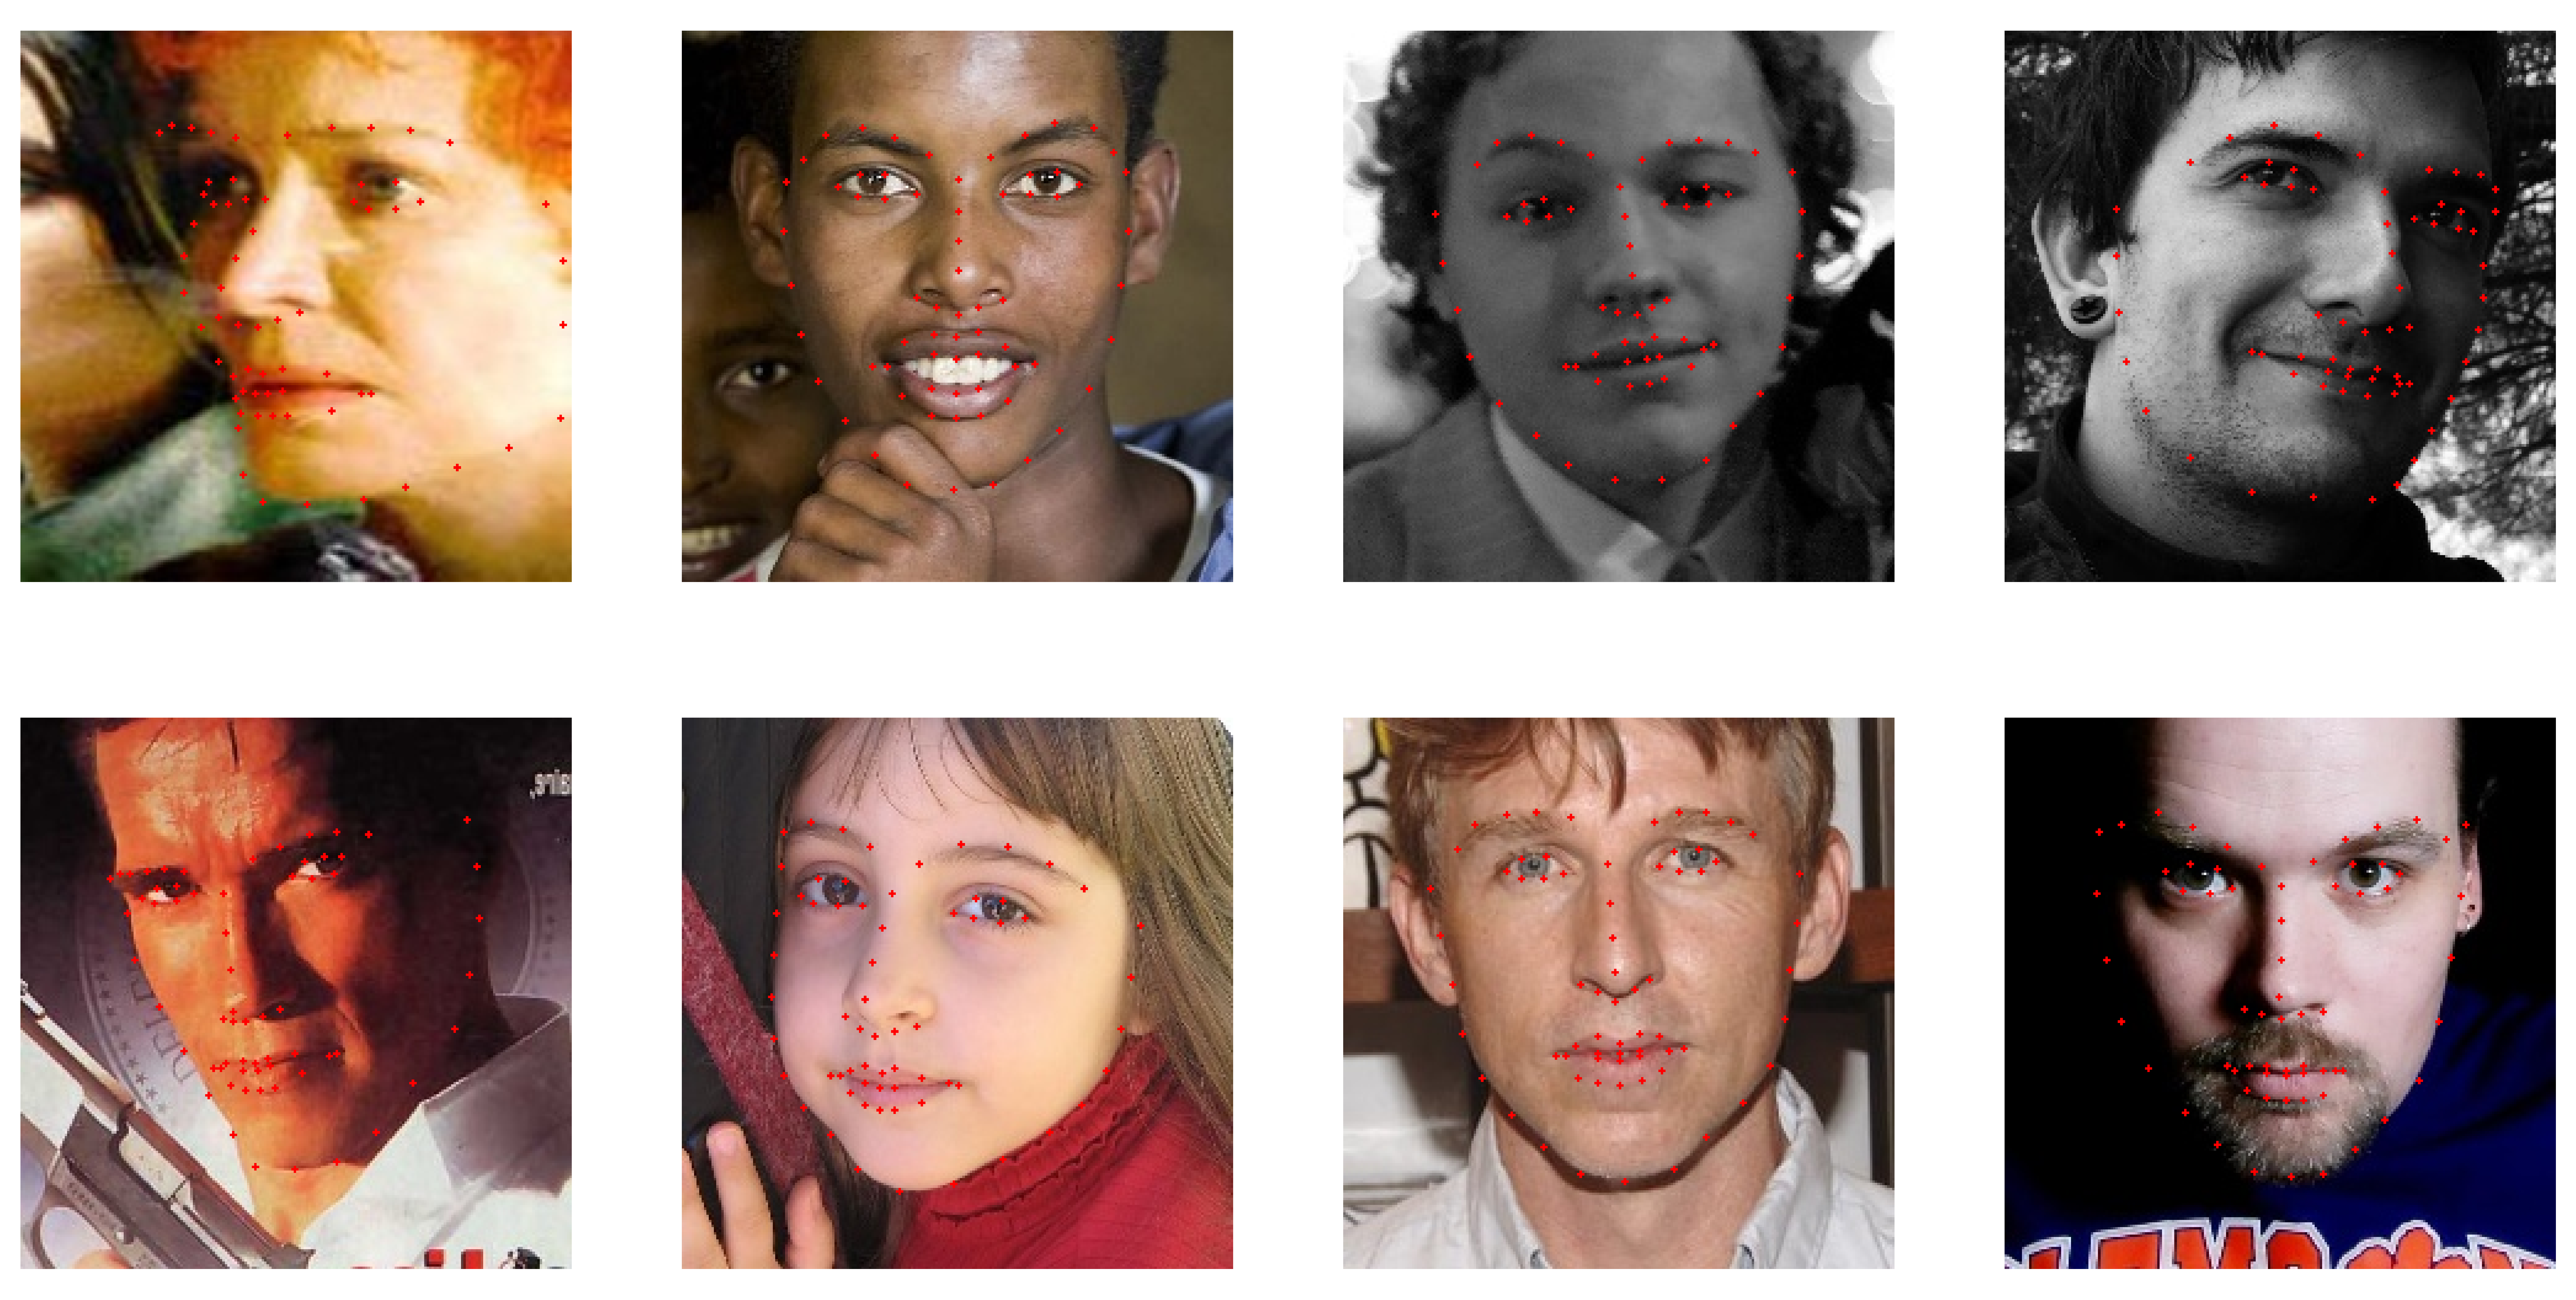

In [26]:
plt.figure(figsize = (16, 8), dpi = 600)
plt.axis('off')
for image_index in range(8):
    index = np.random.randint(low = 0, high = len(labels_df))
    image_name = labels_df['filename'].iloc[index]
    image = cv2.imread(os.path.join(dataset_dir, 'Images', image_name))

    landmarks = labels_df[labels_df.columns[1:-1]].iloc[index]

    for i in range(len(landmarks) // 2):
        x, y = landmarks[2*i], landmarks[2*i+1]
        image = cv2.circle(image, center = (int(x), int(y)), radius = 0, color = (0, 0, 255), thickness = 2)

    plt.subplot(2, 4, image_index + 1)
    plt.imshow(image[:, :, ::-1])
    plt.axis('off')
plt.savefig(os.path.join('data', 'figures', 'Landmark detection', '300W', 'Sample images from 300W'))
plt.show()
    
    